### Importing Dependencies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit  ## expit calculates the logistic function

### Creating an artificial dataset

In [2]:
data = {
    "Age": [
        23, 25, 27, 29, 31, 34, 36, 38, 40, 42,
        24, 26, 28, 30, 33, 35, 37, 39, 41, 43,
        22, 27, 32, 34, 36, 39, 44, 46, 48, 50
    ],

    "Income ('000)": [
        25, 32, 38, 45, 50, 42, 65, 72, 55, 80,
        28, 60, 35, 75, 48, 90, 40, 85, 58, 95,
        20, 52, 30, 68, 47, 62, 43, 100, 70, 38
    ],

    "Credit_Score": [
        580, 610, 625, 640, 655, 590, 700, 720, 680, 740,
        570, 690, 600, 710, 630, 760, 620, 750, 665, 780,
        550, 650, 590, 705, 615, 695, 605, 790, 725, 580
    ],

    "Paid_Loan": [
        0, 0, 0, 1, 1, 0, 1, 0, 1, 1,
        0, 1, 0, 1, 0, 1, 0, 1, 1, 1,
        0, 1, 0, 1, 0, 1, 0, 1, 1, 0
    ]
}

df = pd.DataFrame(data)

print(df.head())
print("Total observations:", len(df))

   Age  Income ('000)  Credit_Score  Paid_Loan
0   23             25           580          0
1   25             32           610          0
2   27             38           625          0
3   29             45           640          1
4   31             50           655          1
Total observations: 30


### Standardizing the variables

In [3]:
X_raw = df[["Age", "Income ('000)", "Credit_Score"]]

X_mean = X_raw.mean()
X_std = X_raw.std(ddof = 0)
X_scaled = (X_raw - X_mean) / X_std

### Add intercept column
X = np.column_stack([
    np.ones(len(df)),
    X_scaled.to_numpy()
])

y = df['Paid_Loan'].to_numpy()

### Defining the Logistic Regression Equation

In [12]:
def predict_probability(beta, X):

    z = X @ beta
    p = expit(z)

    return p

### Defining the Likelihood and Log-Likelihood

In [14]:
def log_likelihood(beta, X, y):
    z = X @ beta
    ll = np.sum(
        y * (-np.logaddexp(0, -z))
        +
        (1-y) * (-np.logaddexp(0, z))
    )
    return ll

### Defining the Objective Function

In [18]:
def objective(beta, X, y):

    return -log_likelihood(beta, X, y)

### Perform Maximum Likelihood Estimation

In [19]:
def gradient(beta, X, y):

    p = predict_probability(beta, X)
    
    grad = X.T @ (p-y)

    return grad

### Initialize the Coefficients

In [20]:
initial_beta = np.zeros(4)

### Record Log-Likelihood at every iteration

In [23]:
log_likelihood_history = []

## record initial log-likelihood
log_likelihood_history.append(
    log_likelihood(initial_beta, X, y)
)

def track_progress(beta):

    current_ll = log_likelihood(beta, X, y)

    log_likelihood_history.append(current_ll)

### Running the optimizer

In [24]:
result = minimize(
    fun=objective,
    x0 = initial_beta,
    args=(X,y),
    jac=gradient,
    method='BFGS',
    callback=track_progress,
    options={
        'gtol': 1e-8,
        'maxiter': 1000
    }
)

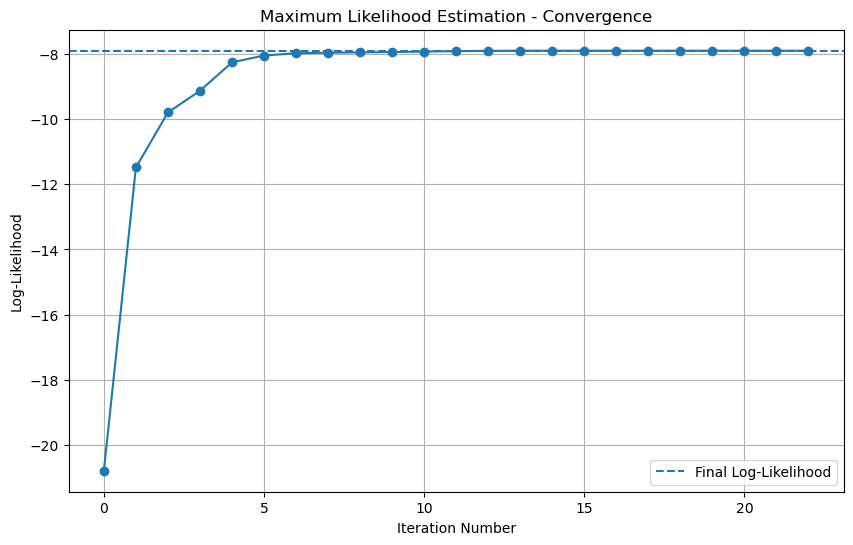

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(len(log_likelihood_history)),
    log_likelihood_history,
    marker='o'
)

plt.axhline(
    y=log_likelihood_history[-1],
    linestyle='--',
    label='Final Log-Likelihood'
)

plt.xlabel("Iteration Number")
plt.ylabel("Log-Likelihood")

plt.title(
    "Maximum Likelihood Estimation - Convergence"
)

plt.legend()
plt.grid(True)

plt.show()

In [25]:
print("Convergence status:", result.success)

print("Message:", result.message)

print("Number of iterations:", result.nit)

print("\nEstimated coefficients:")

coefficient_names = [
    'Intercept',
    'Age',
    'Income',
    'Credit Score'
]

for name, value in zip(
    coefficient_names,
    result.x
):
    print(f"{name}: {value:.6f}")

print("\nMaximum log-likelihood:", -result.fun)

print(
    "Gradient magnitude:",
    np.linalg.norm(result.jac)
)

Convergence status: True
Message: Optimization terminated successfully.
Number of iterations: 22

Estimated coefficients:
Intercept: 0.548155
Age: -0.659153
Income: -0.578265
Credit Score: 4.426851

Maximum log-likelihood: -7.896906003839639
Gradient magnitude: 2.828338169478258e-09
